In [ ]:
!pip install ultralytics opencv-python

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.5/95.5 kB 10.8 MB/s eta 0:00:00


In [ ]:
!python predict.py --source

usage: predict.py [-h] --source SOURCE [--weights WEIGHTS] [--conf CONF]
predict.py: error: argument --source: expected one argument


In [ ]:
!python train.py

Ultralytics 8.4.172 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=medical-pills.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, ov


image 1/1 /content/pill.jpg: 384x640 13 pills, 8.4ms
Speed: 1.3ms preprocess, 8.4ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/outputs/prediction
Displaying predicted image: /content/runs/detect/outputs/prediction/pill.jpg


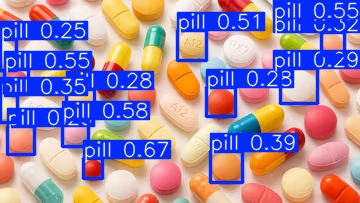

In [ ]:
import os
from IPython.display import Image
from ultralytics import YOLO

# Load our trained model
model_path = '/content/runs/detect/train/weights/best.pt'
source_img = '/content/pill.jpg'
output_dir = 'outputs'

os.makedirs(output_dir, exist_ok=True)

if os.path.exists(source_img):
    # Load the model
    model = YOLO(model_path)
    # Run object detection
    results = model.predict(source=source_img, save=True, project=output_dir, name='prediction', exist_ok=True)

    # Ultralytics saved results under '/content/runs/detect/outputs/prediction/pill.jpg'
    predicted_path = '/content/runs/detect/outputs/prediction/pill.jpg'

    if os.path.exists(predicted_path):
        print(f"Displaying predicted image: {predicted_path}")
        display(Image(predicted_path))
    else:
        # Fallback to alternative path just in case
        fallback_path = os.path.join(output_dir, 'prediction', 'pill.jpg')
        if os.path.exists(fallback_path):
            print(f"Displaying predicted image: {fallback_path}")
            display(Image(fallback_path))
        else:
            print("Prediction completed but output image could not be located.")
else:
    print(f"Source image not found at: {source_img}")